In [8]:
# Kristen Aalbue
# Lab 6
import numpy as np
import matplotlib.pyplot as plt
import os

In [9]:
# taken from lab 3 and 4
def euler_newton(force, times, x0, v0, m,dt):
    # create arrays for x and v
    x = []
    v = []
    # store the initial conditions in the first elements
    x.append(x0)
    v.append(v0)
    
    for i in range(nsteps-1):
        a = force(times[i], x[i], v[i]) / m
        v.append(v[i] + (a * dt))
        x.append(x[i] + (v[i] * dt))
    return x, v
nsteps=1000000
times,dt = np.linspace(0, 10, nsteps, retstep=True)

In [10]:
def spring(t,x,v):
    return (-1)*k*x - b*v

m = 1
k = 9
x0 = 1
v0 = 0

x,v = euler_newton(spring,times, x0, v0, m,dt)


In [11]:
# underdamped,, gamma<2*sqrt(9) // omega naught = sqrt(k/m)
b = 2
x_under,v_under = euler_newton(spring,times,x0,v0,m,dt)

#overdamped,, gamma>2*sqrt(9)
b = 10
x_over,v_over = euler_newton(spring,times,x0,v0,m,dt)

#critically damped,, gamma=2*sqrt(9)
b = 6
x_crit,v_crit = euler_newton(spring,times,x0,v0,m,dt)


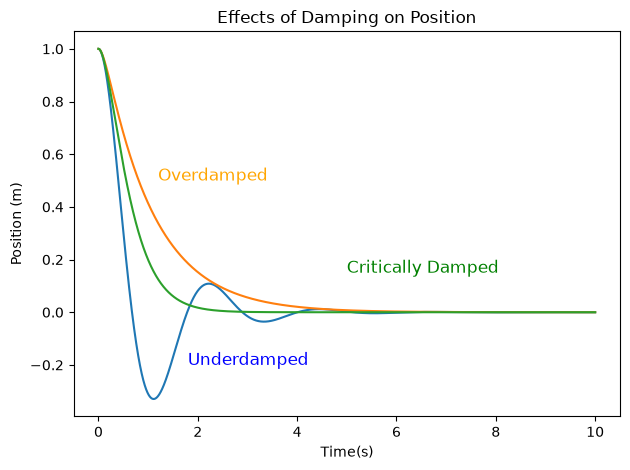

In [12]:
plt.plot(times,x_under)
plt.plot(times,x_over)
plt.plot(times,x_crit)
plt.grid
plt.title("Effects of Damping on Position")
plt.xlabel("Time(s)")
plt.ylabel("Position (m)")
plt.text(1.8,-0.2,"Underdamped",fontsize=12,color='blue')
plt.text(1.2,0.5,"Overdamped",fontsize=12,color='orange')
plt.text(5,0.15,"Critically Damped",fontsize=12,color='green')
plt.tight_layout()
plt.show()


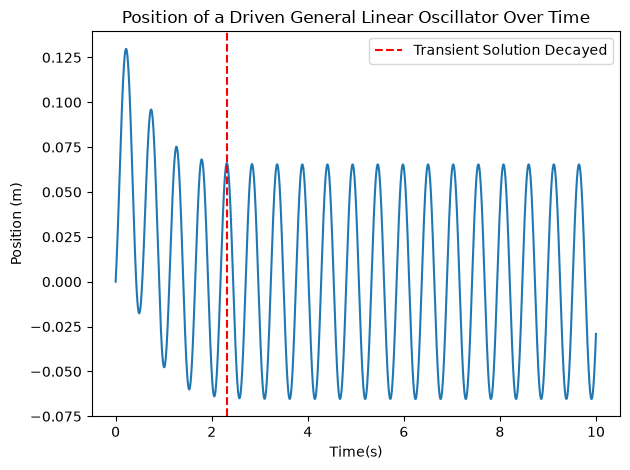

In [13]:
# prob. 3.a),, using the critically damped condition
F0 = 10
omega = 12
t = 15
b=6
x0=0
v0=0.5

def force_spring(t,omega,F0):
    F = F0*(np.cos(omega*t))
    return F
def spring(t,x,v):
    return (-1)*k*x - b*v +force_spring(t,omega,F0)
    
x,v = euler_newton(spring,times,x0,v0,m,dt)

plt.plot(times,x)
plt.grid
plt.title("Position of a Driven General Linear Oscillator Over Time")
plt.xlabel("Time(s)")
plt.ylabel("Position (m)")
plt.axvline(x=2.31,color='red',linestyle="--",label='Transient Solution Decayed')
plt.legend()
plt.tight_layout()
plt.show()

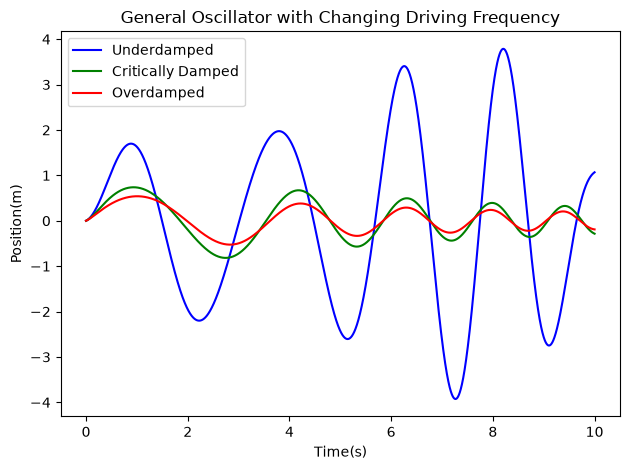

In [14]:
# prob. 3b.)

def force_spring(t,omega,F0):
    omega_d=1+(0.4*t)
    
    # integrate driving force of omega (omega_d) to find change wrt time
    F = F0*(np.cos(t+(0.2*t**2)))
    return F
# underdamped, critically damped, overdamped
for b in [0.5,6,10]:
    x,v = euler_newton(spring,times,x0,v0,m,dt)
    if b == 0.5:
        plt.plot(times,x,label='Underdamped',color='blue')
    if b == 6:
        plt.plot(times,x,label='Critically Damped',color='green')
    if b == 10:
        plt.plot(times,x,label='Overdamped',color='red')

nsteps=10000
times,dt = np.linspace(0, 10, nsteps, retstep=True)
x,v = euler_newton(spring,times,x0,v0,m,dt)

plt.grid
plt.title("General Oscillator with Changing Driving Frequency")
plt.xlabel("Time(s)")
plt.ylabel("Position(m)")
plt.legend()
plt.tight_layout()
plt.show()

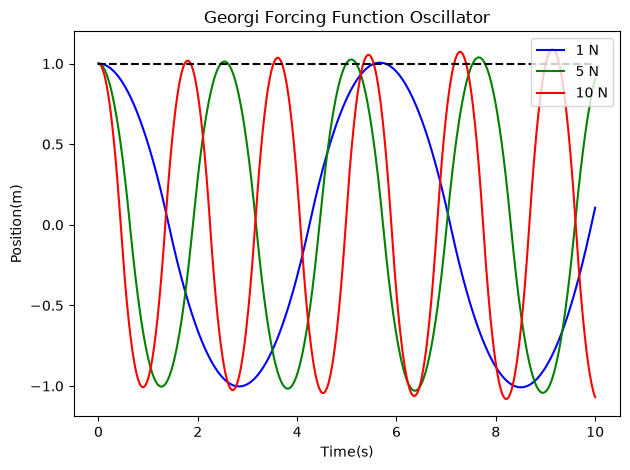

In [15]:
# prob. 4),, Georgi (1.120):
    # m(d^2/dt^2)x = -F0 for x>0, F0 for x<0, 0 for x=0

def georgi(t,x,v):
    if x>0:
        return -F0
    if x<0:
        return F0
    if x==0:
        return 0

x0 = 1
v0 = 0

for F0 in [1,5,10]:
    x,v = euler_newton(georgi,times,x0,v0,m,dt)
    if F0==1:
        plt.plot(times,x,label='1 N',color='blue')
    if F0==5:
        plt.plot(times,x,label='5 N',color='green')
    if F0==10:
        plt.plot(times,x,label='10 N',color='red')

# figure out how to keep the oscillations from increasing with time !!!
plt.plot([0,10],[1,1],c="black",ls="--")
plt.grid
plt.title("Georgi Forcing Function Oscillator")
plt.xlabel("Time(s)")
plt.ylabel("Position(m)")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

With the Georgi Equation (1.120), we see a sinusoidal curve where if the position is positive, the force is negative and vice versa. When at origin, the force = 0. The object fluctuates moving through the equilibrium point with a restorative force pulling it back to equilibrium. We see this motion in things like Slinky's, car suspensions, guitar strings, gravity, and more.